**PRACTICAL LECTURE 3**

**PART1. Autoencoders**

**2025-2026**

1. Import libraries

In [1]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST
from matplotlib import pyplot as plt
import numpy as np

2. Convert vector to image
The following function allows to convert a vector to an image

In [2]:
def to_img(x):
    x = 0.5 * (x + 1)
    x = x.view(x.size(0), 28, 28)
    return x

3. We now write a function which allows to display the images using the imshow() function.

In [3]:
def display_images(in_, out, n=1):
    for N in range(n):
        if in_ is not None:
            in_pic = to_img(in_.cpu().data)
            plt.figure(figsize=(18, 6))
            for i in range(4):
                plt.subplot(1,4,i+1)
                plt.imshow(in_pic[i+4*N])
                plt.axis('off')
        out_pic = to_img(out.cpu().data)
        plt.figure(figsize=(18, 6))
        for i in range(4):
            plt.subplot(1,4,i+1)
            plt.imshow(out_pic[i+4*N])
            plt.axis('off')

4. Define a data loading step and load the MNIST dataset (train and test sets).

In [4]:
batch_size = 256

img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = MNIST('./data', transform=img_transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

test_dataset = MNIST('./data', train=False, transform=img_transform, download=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

5. Fix the used device

In [5]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

6. Define the Autoencoder model architecture and reconstruction loss
with :
n = 28 x 28 = 784

A. Use d = 30  for standard AE (under-complete hidden layer)

B. Use d = 500 for denoising AE (over-complete hidden layer)

C. Compute **by hand** the number of parameters of the autoencoder for d = 30 and for d = 500, then check your answer with `sum(p.numel() for p in model.parameters())`.

D. Explain the difference between standard AE and denoising AE. Why would an over-complete standard AE (d = 500, no noise) be useless?
Analyse the results and conclude.

In [6]:
#6.a
d=30

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, d),
            nn.Tanh(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 28 * 28),
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = Autoencoder().to(device)
criterion = nn.MSELoss()

In [7]:
#6.b
d = 500
model_dae = Autoencoder().to(device)
criterion_dae = nn.MSELoss()

Réponse 6.c :

Le nombre de paramètres d'une couche linéaire est donné par la formule qu'on trouve dans le cours : $(n_{in} + 1) \cdot n_{out}$ (le $+1$ correspond au biais)

On regarde l'architecture de l'autoencodeur :

"self.encoder = nn.Sequential(nn.Linear(28 * 28, d), nn.Tanh())

self.decoder = nn.Sequential(nn.Linear(d, 28 * 28), nn.Tanh())"

Donc on a 2 couches linéaires : `Linear(784, d)` et `Linear(d, 784)`. Les `Tanh` n'ont aucun paramètre (ce sont juste des fonctions d'activation, sans poids à apprendre)

On a $n = 28 \times 28 = 784$, donc de façon générale :

- encodeur : $(784 + 1) \cdot d = 785 \cdot d$
- décodeur : $(d + 1) \cdot 784 = 784 \cdot d + 784$

Total = $1569 \cdot d + 784$

Pour d = 30 :

- encodeur : (784 + 1)·30 = 23 550 (nn.Linear(784, 30))
- décodeur : (30 + 1)·784 = 24 304 (nn.Linear(30, 784))

Total = 47 854

Pour d = 500 :

- encodeur : (784 + 1)·500 = 392 500 (nn.Linear(784, 500))
- décodeur : (500 + 1)·784 = 392 784 (nn.Linear(500, 784))

Total = 785 284

In [8]:
# vérification
for d in [30, 500]:
    m = Autoencoder()
    print(d, sum(p.numel() for p in m.parameters()))

30 47854
500 785284


6.d
Réponse 6.D :

seuls d et l'entrée changent, et on voit que :

- AE standard (d = 30) : entrée = cible = l'image x. Comme d = 30 < n = 784 (under-complete), le code est obligé de compresser l'image.
- AE débruiteur (d = 500) : l'entrée est une image abîmée (img_bad, Dropout) mais la cible reste l'image propre img. Le réseau doit réparer l'image.

un AE over-complete standard (d = 500, sans bruit) serait inutile car :

D'après 6.C, il a 785 284 paramètres (contre 47 854 pour d = 30) et un code presque aussi grand que l'image. Comme entrée = cible, la loss est très faible mais il n'apprend rien sur la structure des chiffres. Avec du bruit, recopier l'entrée donne une sortie fausse, donc le réseau doit apprendre les corrélations entre pixels voisins.

Analyse :

- AE standard : loss finale ≈ 0.065, chiffres  un peu flous
- AE débruiteur : loss finale ≈ 0.039, reconstructions plus nettes malgré l'entrée abîmée

Conclusion :

Les deux modèles évitent l'identité par un mécanisme différent : le goulot d'étranglement (d petit) pour l'AE standard, le bruit sur l'entrée pour le débruiteur. La loss plus basse du débruiteur vient en partie de sa plus grande capacité (500 contre 30), donc la taille du code seule ne suffit pas : il faut une contrainte pour que l'AE apprenne la structure des données.

7. Configure the optimiser. We use here : learning_rate equals to 1e-3

In [9]:
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)

In [10]:
optimizer_dae = torch.optim.Adam(
    model_dae.parameters(),
    lr=learning_rate,
)

8. Train the standard autoencoder and the denoising autoencoder using the following code :

epoch [1/20], loss:0.2119
epoch [2/20], loss:0.1442
epoch [3/20], loss:0.1305
epoch [4/20], loss:0.1073
epoch [5/20], loss:0.1068
epoch [6/20], loss:0.0932
epoch [7/20], loss:0.0889
epoch [8/20], loss:0.0834
epoch [9/20], loss:0.0780
epoch [10/20], loss:0.0793
epoch [11/20], loss:0.0729
epoch [12/20], loss:0.0696
epoch [13/20], loss:0.0642
epoch [14/20], loss:0.0616
epoch [15/20], loss:0.0681
epoch [16/20], loss:0.0592
epoch [17/20], loss:0.0554
epoch [18/20], loss:0.0576
epoch [19/20], loss:0.0594
epoch [20/20], loss:0.0612


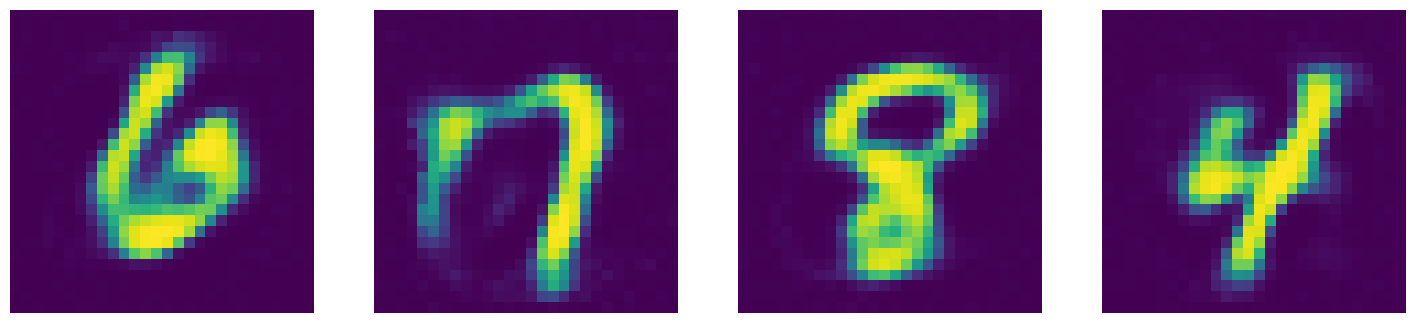

In [11]:
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        # noise = do(torch.ones(img.shape)).to(device)
        # img_bad = (img * noise).to(device)  # comment out for standard AE
        # ===================forward=====================
        output = model(img)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(None, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

Code ci dessous reprensente le denoising AE :

epoch [1/20], loss:0.0762
epoch [2/20], loss:0.0559
epoch [3/20], loss:0.0558
epoch [4/20], loss:0.0517
epoch [5/20], loss:0.0489
epoch [6/20], loss:0.0455
epoch [7/20], loss:0.0471
epoch [8/20], loss:0.0493
epoch [9/20], loss:0.0444
epoch [10/20], loss:0.0447
epoch [11/20], loss:0.0432
epoch [12/20], loss:0.0424
epoch [13/20], loss:0.0453
epoch [14/20], loss:0.0406
epoch [15/20], loss:0.0420
epoch [16/20], loss:0.0402
epoch [17/20], loss:0.0438
epoch [18/20], loss:0.0391
epoch [19/20], loss:0.0397
epoch [20/20], loss:0.0419


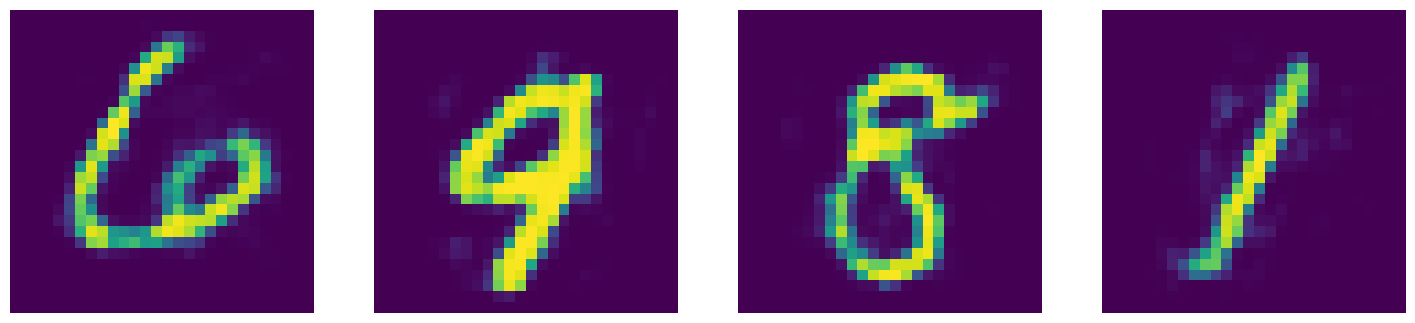

In [12]:
num_epochs = 20
do = nn.Dropout()
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        noise = do(torch.ones(img.shape)).to(device)
        img_bad = (img * noise).to(device)  # comment out for standard AE
        # ===================forward=====================
        output = model_dae(img_bad)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion_dae(output, img.data)
        # ===================backward====================
        optimizer_dae.zero_grad()
        loss.backward()
        optimizer_dae.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(None, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

9. The Dropout noise above sets random pixels to zero. Write a second version of the denoising AE (d = 500) where the noise is **additive Gaussian noise** of standard deviation $\sigma = 0.5$ (be careful to keep the pixel values in $[-1, 1]$). Display noisy inputs and reconstructions, and compare with the Dropout version.

epoch [1/20], loss:0.0493
epoch [2/20], loss:0.0292
epoch [3/20], loss:0.0272
epoch [4/20], loss:0.0245
epoch [5/20], loss:0.0241
epoch [6/20], loss:0.0211
epoch [7/20], loss:0.0215
epoch [8/20], loss:0.0220
epoch [9/20], loss:0.0203
epoch [10/20], loss:0.0208
epoch [11/20], loss:0.0201
epoch [12/20], loss:0.0198
epoch [13/20], loss:0.0194
epoch [14/20], loss:0.0196
epoch [15/20], loss:0.0191
epoch [16/20], loss:0.0188
epoch [17/20], loss:0.0199
epoch [18/20], loss:0.0196
epoch [19/20], loss:0.0184
epoch [20/20], loss:0.0199


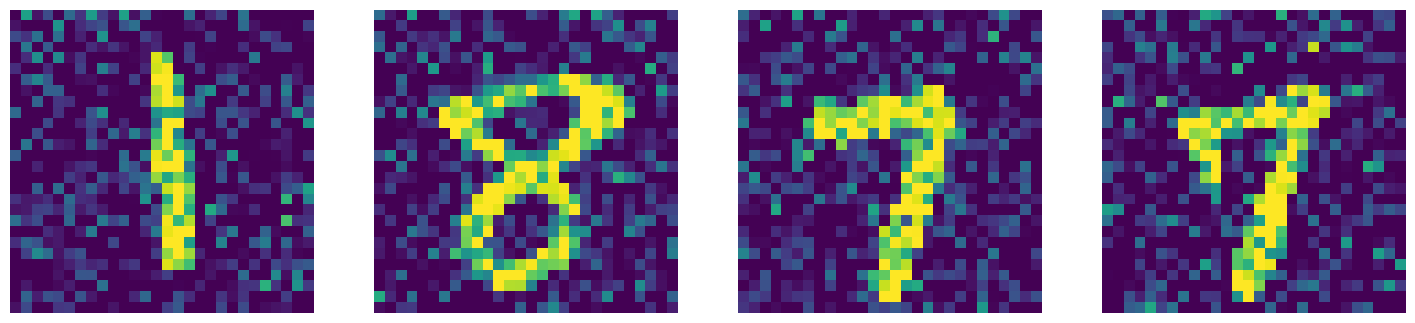

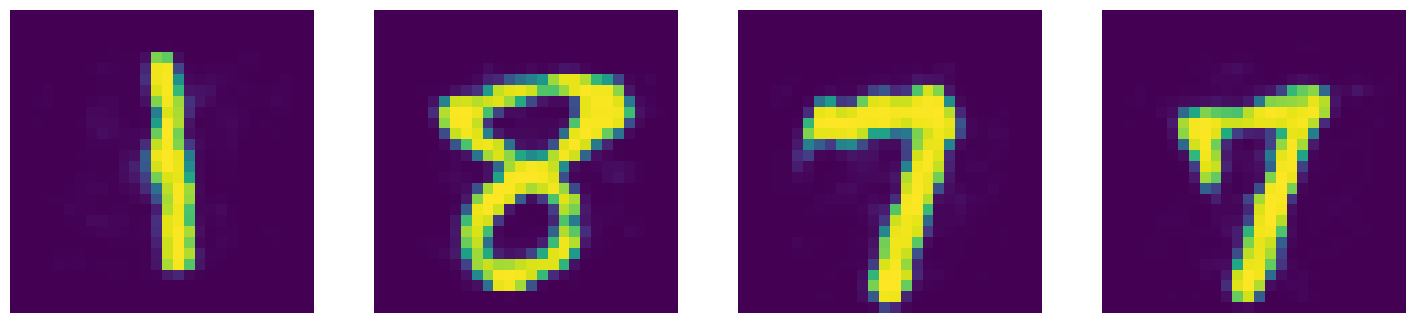

In [13]:
d = 500
model_gauss = Autoencoder().to(device)
criterion_gauss = nn.MSELoss()
learning_rate = 1e-3

optimizer_gauss = torch.optim.Adam(
    model_gauss.parameters(),
    lr=learning_rate,
)
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)

        # on remplace bruit dropout par gaussian
        noise = (torch.randn_like(img) * 0.5).to(device)
        # "additif"
        img_bad = img + noise
        # les valeurs de pixels doivent etre comprises entre -1 et 1
        img_bad = torch.clamp(img_bad, min = -1.0, max=1.0)
        
        # ===================forward=====================
        output = model_gauss(img_bad)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion_gauss(output, img.data)
        # ===================backward====================
        optimizer_gauss.zero_grad()
        loss.backward()
        optimizer_gauss.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(img_bad, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

10. Visualise a few kernels of the encoder :

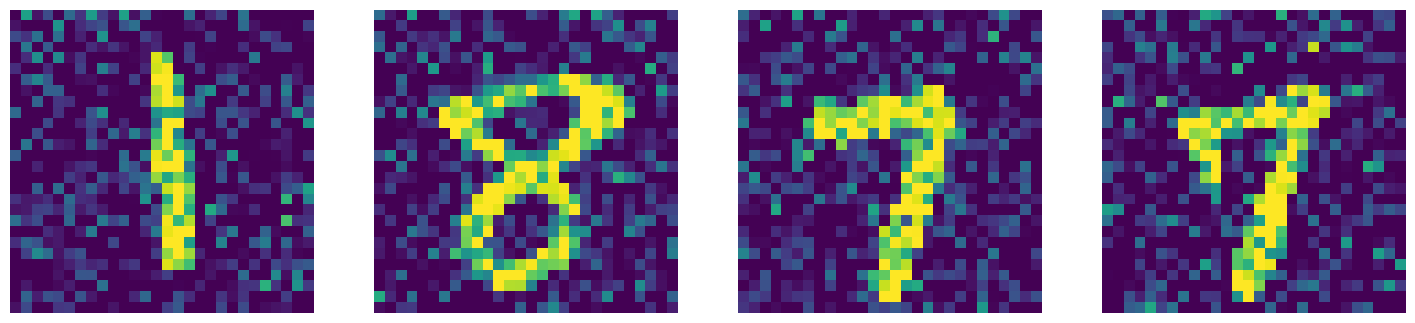

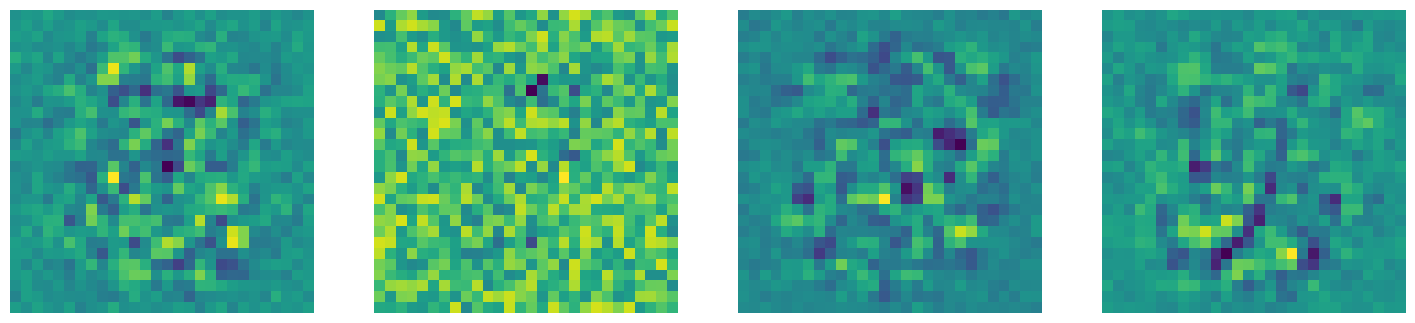

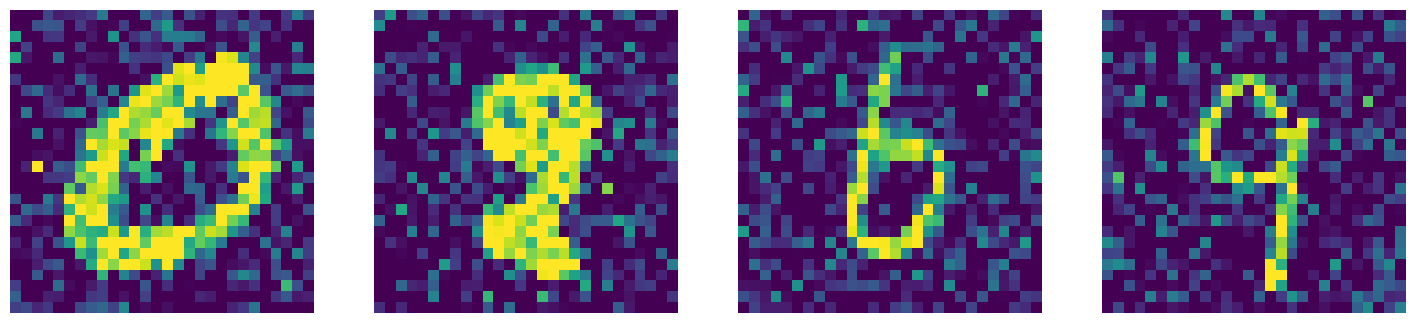

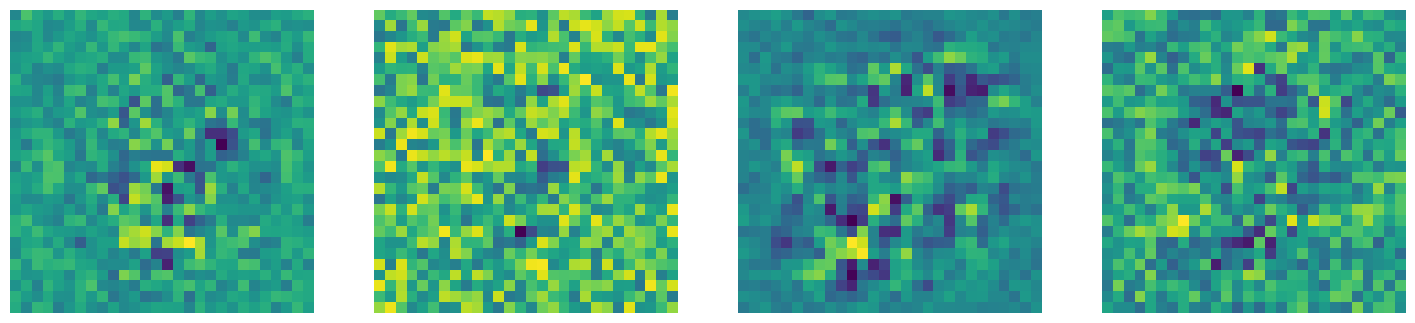

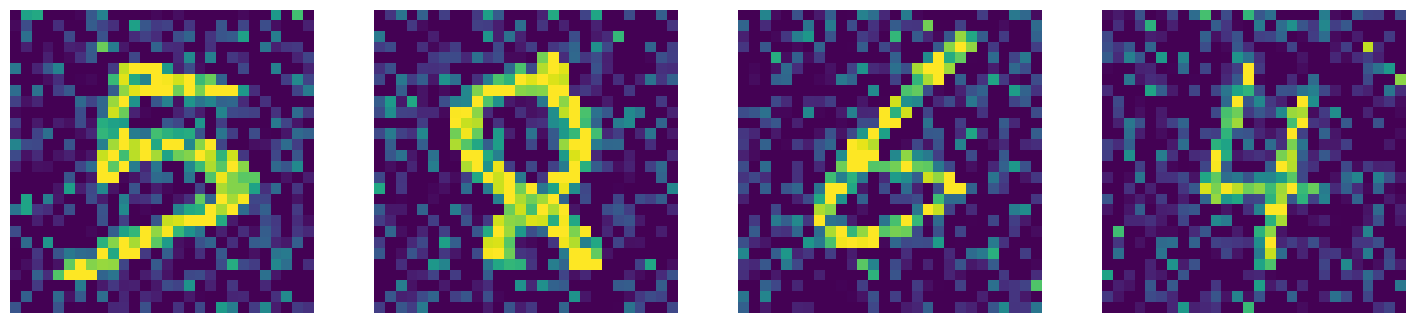

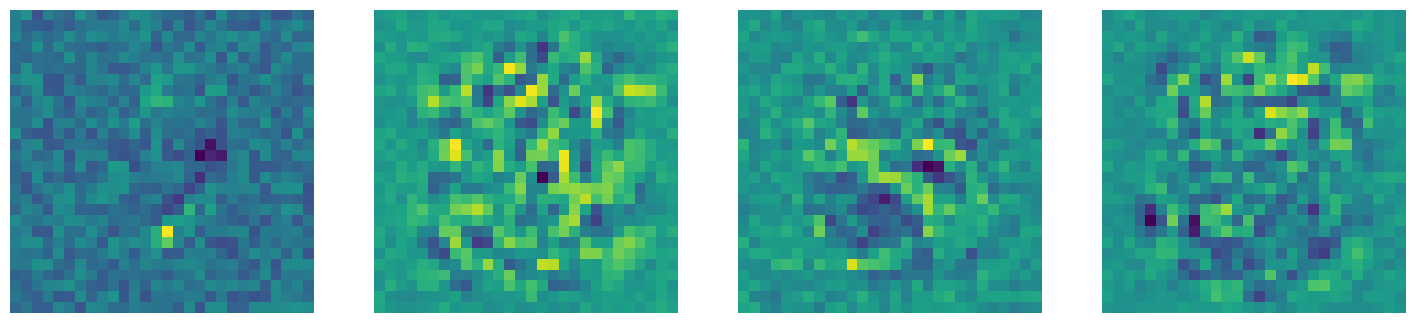

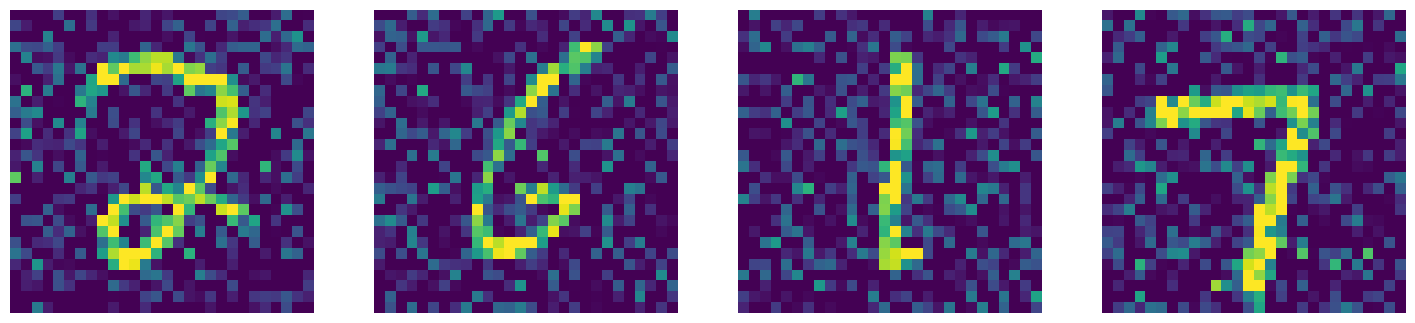

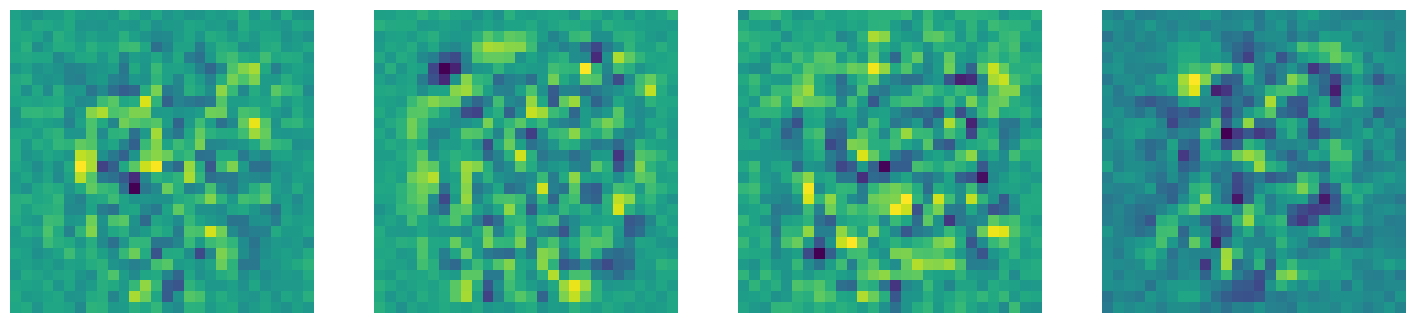

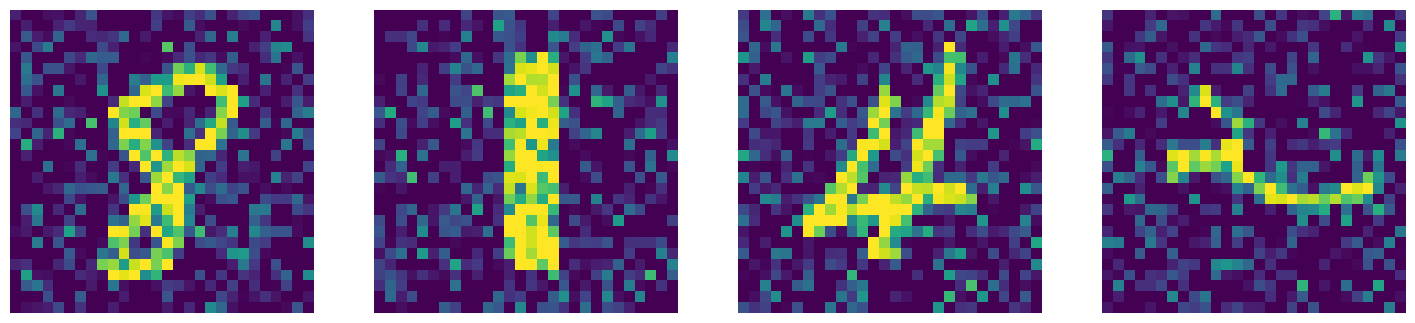

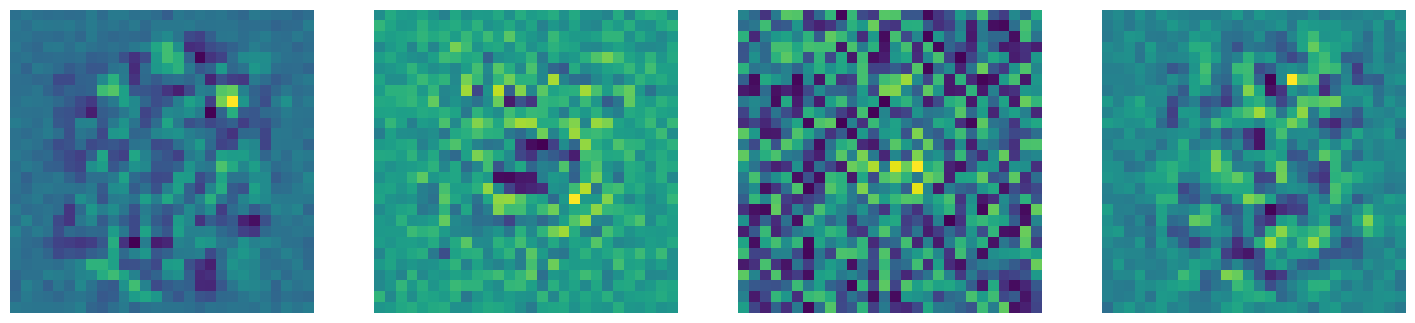

In [14]:
display_images(img_bad, model_gauss.encoder[0].weight, 5)

11. Latent space. Train a standard autoencoder with **d = 2** (5 epochs are enough). Encode all the images of the test set and plot the 2-D codes as a scatter plot, with one color per digit (use the labels of `test_dataset`). Which digits are well separated? Which ones overlap? Is this surprising, given that the labels were never used during training?

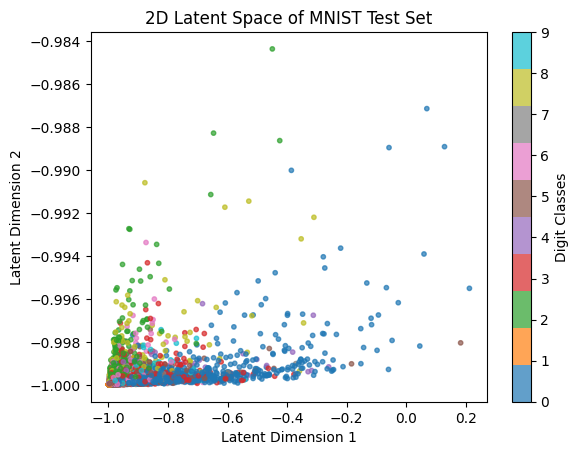

In [15]:
d = 2
model_2d = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model_2d.parameters(),
    lr=learning_rate,
)

num_epochs = 5

model_2d.train()

for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        output = model_2d(img)
        loss = criterion(output, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

latent_codes = []
labels_list = []

model_2d.eval()
with torch.no_grad(): # No need to track gradients for evaluation
    for data in test_dataloader:
        img, label = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        code = model_2d.encoder(img)
        latent_codes.append(code)
        labels_list.append(label) 
# on fusuonne les petits lots
latent_codes = torch.cat(latent_codes).numpy()
labels_list = torch.cat(labels_list).numpy()

plt.figure()
scatter = plt.scatter(latent_codes[:, 0], latent_codes[:, 1], c=labels_list, cmap='tab10', alpha=0.7, s=10)
plt.colorbar(scatter, ticks=range(10), label='Digit Classes')
plt.title("2D Latent Space of MNIST Test Set")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

Réponse question 11 :
- avec d = 2, l’espace latent n'est pas très lisible (c'est très concentrés dans un coin) c'est dû au fait que l’activation tanh de l’encodeur sature (car avec que 2 neurones les poids grandissent et les sorties collent aux bornes [-1,+1])
- chiffre bien séparé : le 0 s'étale loin des autres classes
- chiffres qui se chevauchent : toutes les autres classes sont mélangées dans le coin saturé
- c'est pas surprenant car l’autoencodeur n’utilise jamais les labels, mais pour reconstruire les images il doit placer proches les images qui se ressemblent en pixels et les images d’un même chiffre se ressemblent plus entre elles qu’avec les autres mais 2 dimensions sont trop peu pour séparer 10 classes, et la saturation du tanh écrase une grande partie des points

12. Write a function `test_mse(model)` returning the mean reconstruction error on the **test set**. Train a standard AE (5 epochs each) for d ∈ {2, 10, 30, 100} and plot the test MSE as a function of d. Comment the curve.

dim 2 : epoch [1/5], loss:0.5342
dim 2 : epoch [2/5], loss:0.3364
dim 2 : epoch [3/5], loss:0.2973
dim 2 : epoch [4/5], loss:0.2910
dim 2 : epoch [5/5], loss:0.2843
dim 10 : epoch [1/5], loss:0.2894
dim 10 : epoch [2/5], loss:0.2552
dim 10 : epoch [3/5], loss:0.2151
dim 10 : epoch [4/5], loss:0.2189
dim 10 : epoch [5/5], loss:0.1867
dim 30 : epoch [1/5], loss:0.2055
dim 30 : epoch [2/5], loss:0.1592
dim 30 : epoch [3/5], loss:0.1256
dim 30 : epoch [4/5], loss:0.1106
dim 30 : epoch [5/5], loss:0.0958
dim 100 : epoch [1/5], loss:0.1076
dim 100 : epoch [2/5], loss:0.0648
dim 100 : epoch [3/5], loss:0.0482
dim 100 : epoch [4/5], loss:0.0371
dim 100 : epoch [5/5], loss:0.0379


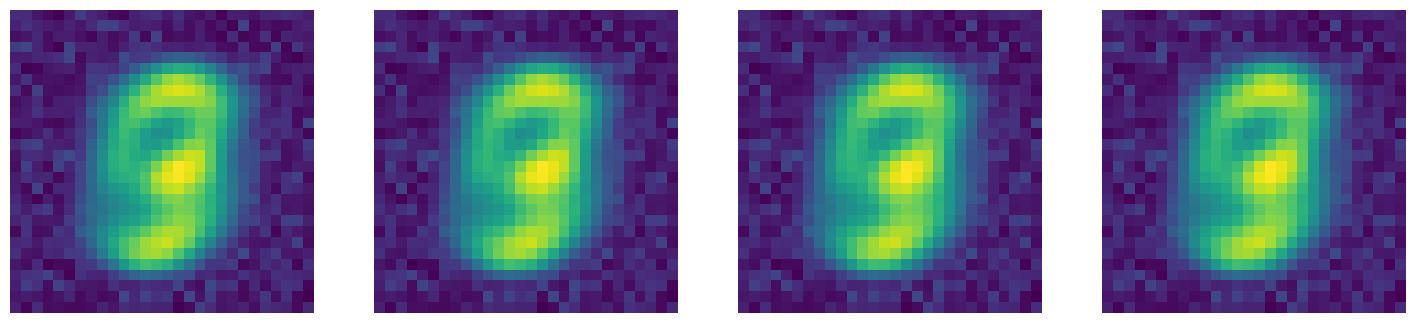

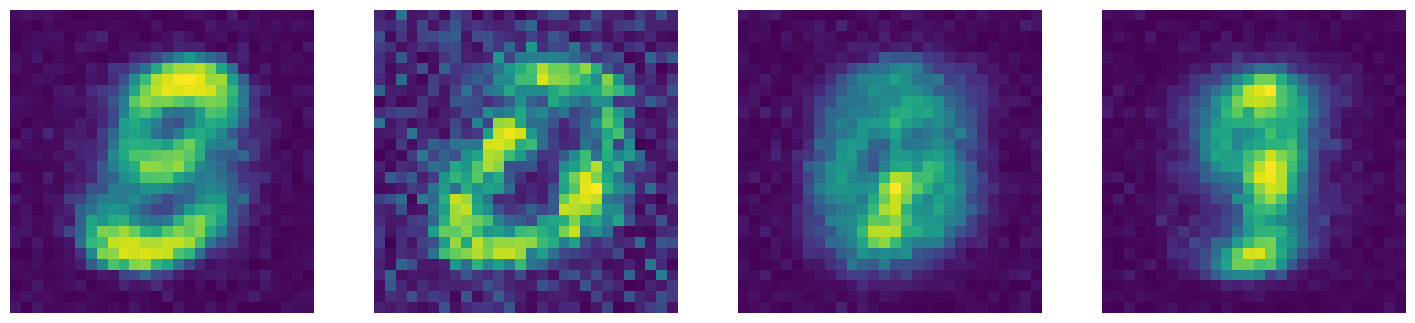

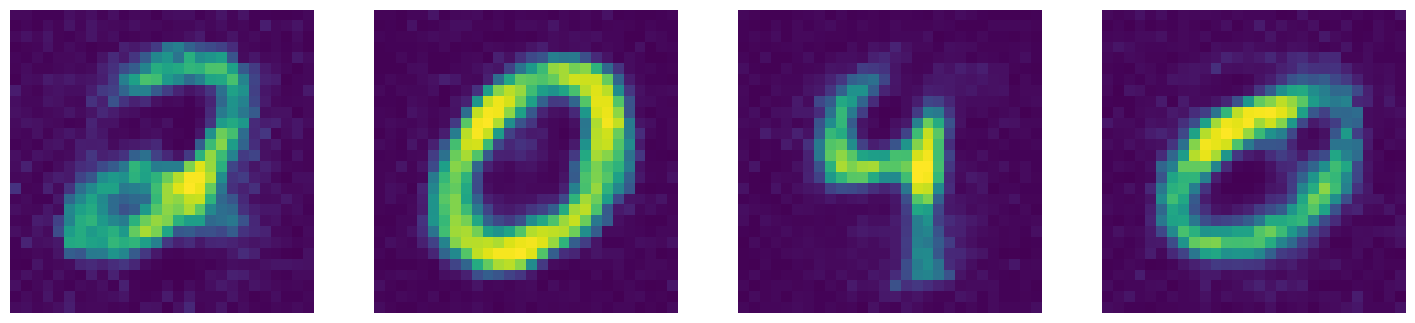

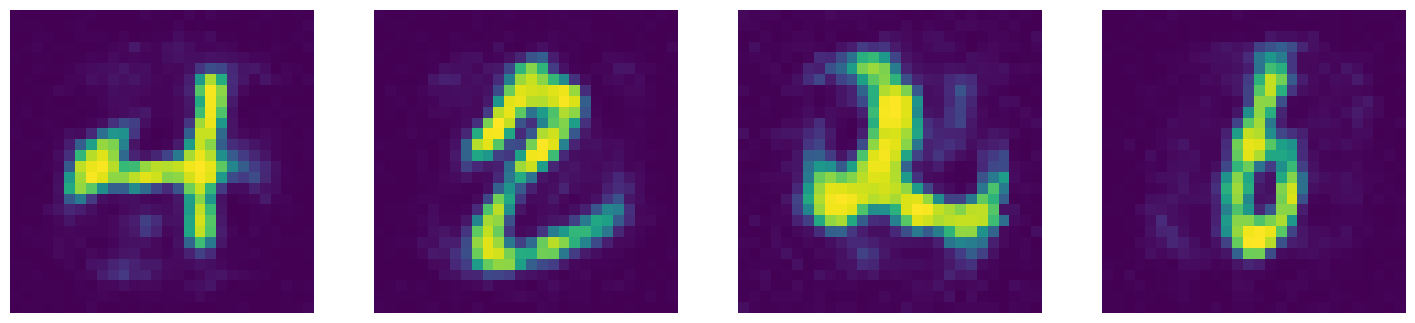

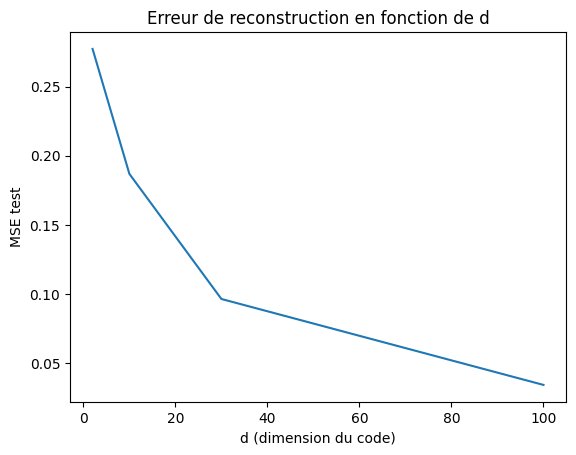

In [16]:
def test_mse(model):
    model.eval()
    total = 0
    n = 0

    with torch.no_grad():
        for data in test_dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model(img)
            dist_carre = (output - img) ** 2
            total = total + (dist_carre).sum().item()
            
            n += img.shape[0] * img.shape[1]
    return total / n

liste_mse_model = []

dim_liste = [2, 10, 30, 100]

for d_valeur in dim_liste :

    d = d_valeur
    model_2d = Autoencoder().to(device)
    criterion = nn.MSELoss()
    learning_rate = 1e-3

    optimizer = torch.optim.Adam(
        model_2d.parameters(),
        lr=learning_rate,
    )

    num_epochs = 5
    for epoch in range(num_epochs):
        for data in dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model_2d(img)
            loss = criterion(output, img.data)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f'dim {d} : epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
    display_images(None, output)

    liste_mse_model.append(test_mse(model_2d))

plt.figure()
plt.plot(dim_liste, liste_mse_model)
plt.xlabel("d (dimension du code)")
plt.ylabel("MSE test")
plt.title("Erreur de reconstruction en fonction de d")
plt.show()

13. Analyse the obtained results.

- plus les dimensions montent plus la MSE baisse, elle est maximale à d=2 ce qui est logique car on perd beaucoup d'informations en compressant une image en 2 dimensions seulement
- plus d monte plus l'espace latent a de la capacité de stockage donc moins de perte d'info donc l'erreur quadratique moyenne de reconstruction baisse

- les séries d'images reconstruites sont floues et pas nettes pour d=2
- plus d monte moins il y a de bruits et plus c'est net (on voit mieux les contours)

14. Change the parameters of the Autoencoder (activation functions, number of layers, learning rate…) and analyse their impact. Conclude.

dim 2 : epoch [1/5], loss:0.1877
dim 2 : epoch [2/5], loss:0.1752
dim 2 : epoch [3/5], loss:0.1768
dim 2 : epoch [4/5], loss:0.1627
dim 2 : epoch [5/5], loss:0.1680
dim 10 : epoch [1/5], loss:0.0838
dim 10 : epoch [2/5], loss:0.0800
dim 10 : epoch [3/5], loss:0.0626
dim 10 : epoch [4/5], loss:0.0663
dim 10 : epoch [5/5], loss:0.0631
dim 30 : epoch [1/5], loss:0.0424
dim 30 : epoch [2/5], loss:0.0300
dim 30 : epoch [3/5], loss:0.0289
dim 30 : epoch [4/5], loss:0.0256
dim 30 : epoch [5/5], loss:0.0236
dim 100 : epoch [1/5], loss:0.0330
dim 100 : epoch [2/5], loss:0.0207
dim 100 : epoch [3/5], loss:0.0163
dim 100 : epoch [4/5], loss:0.0134
dim 100 : epoch [5/5], loss:0.0117


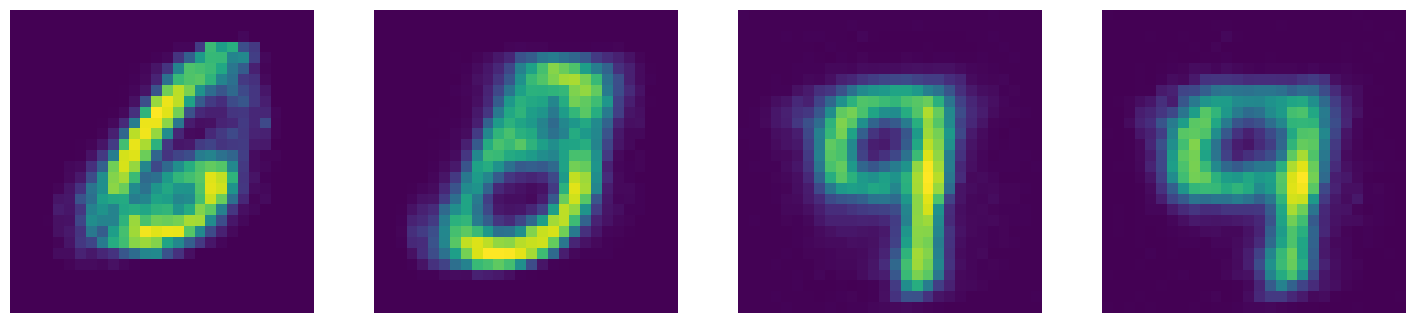

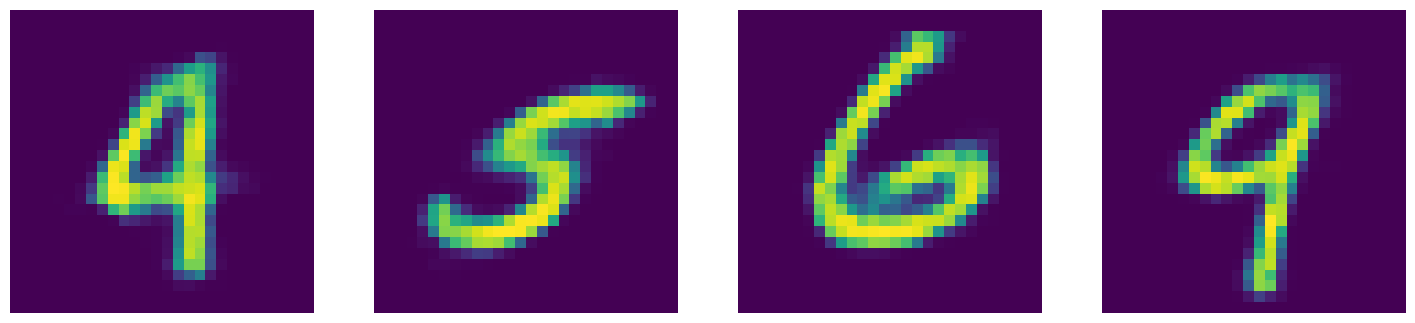

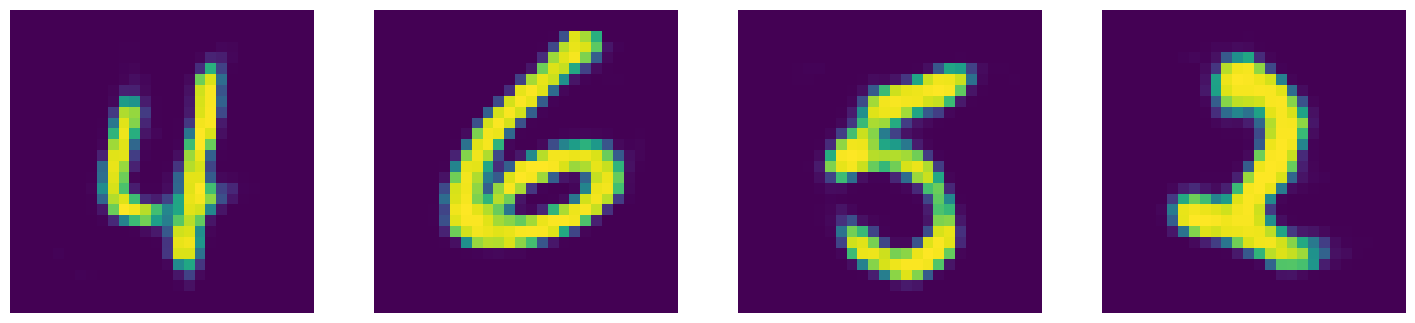

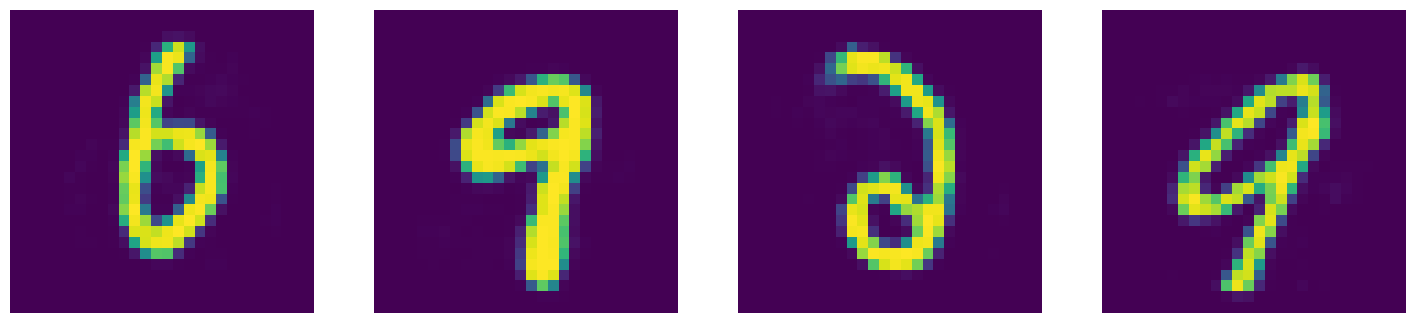

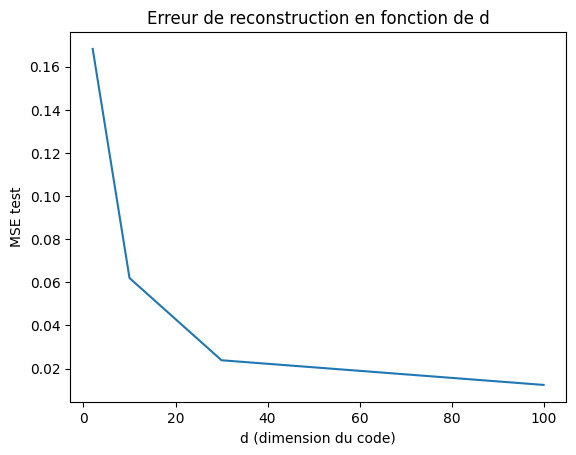

In [17]:
d=30

class Autoencoder_v2(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 50 * 50),
            nn.ReLU(),
            nn.Linear(50 * 50, d),

        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 50 * 50),
            nn.ReLU(),
            nn.Linear(50*50, 28 * 28),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

liste_mse_model = []

dim_liste = [2, 10, 30, 100]

for d_valeur in dim_liste :

    d = d_valeur
    model_2d = Autoencoder_v2().to(device)
    criterion = nn.MSELoss()
    learning_rate = 1e-3

    optimizer = torch.optim.Adam(
        model_2d.parameters(),
        lr=learning_rate,
    )

    num_epochs = 5
    for epoch in range(num_epochs):
        for data in dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model_2d(img)
            loss = criterion(output, img.data)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f'dim {d} : epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
    display_images(None, output)

    liste_mse_model.append(test_mse(model_2d))

plt.figure()
plt.plot(dim_liste, liste_mse_model)
plt.xlabel("d (dimension du code)")
plt.ylabel("MSE test")
plt.title("Erreur de reconstruction en fonction de d")
plt.show()

On remarque que selon les fonctions d'activation et autres paramètres choisis, les séries d'images diffèrent en netteté : là on a un résultat bien plus propre par exemple ce qui est logique avce 2500 neurones, une activation ReLU en couche cachée et Tahn en sortie. En effet, on avait testé Sigmoid en sortie mais sur des images dans [−1, 1] ça empêche l'apprentissage.
En contrepartie c'est beaucoup plus long et coûteux.

**PART2. Convolutional Neural Networks**

1. Import the libraries and set the parameters

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


def set_default(figsize=(10, 10), dpi=100):
    plt.style.use(['dark_background', 'bmh'])
    plt.rc('axes', facecolor='k')
    plt.rc('figure', facecolor='k')
    plt.rc('figure', figsize=figsize, dpi=dpi)

set_default()

# function to count number of parameters
def get_n_params(model):
    n = 0
    for p in list(model.parameters()):
        n += p.nelement()
    return n

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

2. Load the Dataset (MNIST) using PyTorch DataLoader utilities and visualize some images :

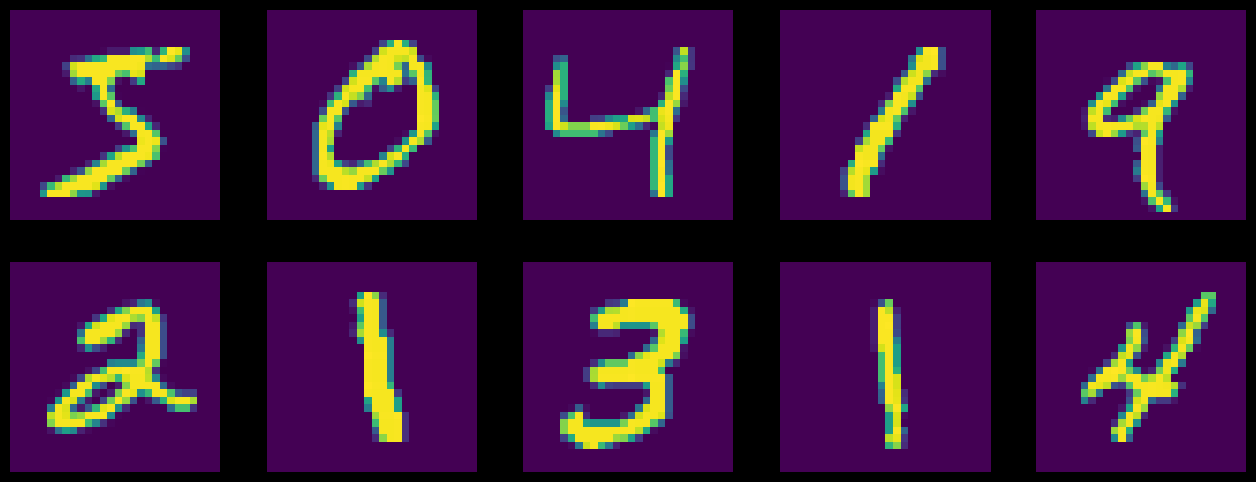

In [19]:
input_size  = 28*28   # images are 28x28 pixels
output_size = 10      # there are 10 classes

train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=64, shuffle=True)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False, transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=1000, shuffle=True)

plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    image, _ = train_loader.dataset.__getitem__(i)
    plt.imshow(image.squeeze().numpy())
    plt.axis('off');

3. Create the model classes

In [20]:
class FC2Layer(nn.Module):
    def __init__(self, input_size, n_hidden, output_size):
        super(FC2Layer, self).__init__()
        self.input_size = input_size
        self.network = nn.Sequential(
            nn.Linear(input_size, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, output_size),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, x):
        x = x.view(-1, self.input_size)
        return self.network(x)

class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super(CNN, self).__init__()
        self.n_feature = n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)
        self.fc1 = nn.Linear(n_feature*4*4, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x, verbose=False):
        if verbose: print(tuple(x.shape))
        x = self.conv1(x)
        if verbose: print(tuple(x.shape))
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        if verbose: print(tuple(x.shape))
        x = self.conv2(x)
        if verbose: print(tuple(x.shape))
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        if verbose: print(tuple(x.shape))
        x = x.view(-1, self.n_feature*4*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.log_softmax(x, dim=1)
        return x

4. a. For an input image of size 1×28×28, compute **by hand** the shape of the tensor after each layer of the CNN (conv1, pooling, conv2, pooling). Justify the value `n_feature*4*4` used in `fc1`.

   b. Use the argument `verbose` of `forward` to print these shapes and check your answer.

   c. Compute by hand the number of parameters of the CNN for `n_feature = 6` and of the FC2Layer for `n_hidden = 8`. Check with `get_n_params`.

Réponse 4.a :

D'après le cours (Relationship 6), la taille de sortie d'une convolution ou d'un pooling est :

$$o = \left\lfloor \frac{i + 2p - k}{s} \right\rfloor + 1$$

avec $i$ la taille d'entrée, $k$ la taille du noyau, $p$ le padding et $s$ le stride.

On choisit cette formule car c'est le cas général : elle contient les relations 1, 2 et 5 du cours doc en une formule on a à la fois les convolutions et les poolings du réseau, le pooling fonctionnant comme une convolution.

"self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)"

Donc `conv1` et `conv2` ont $k=5$, $s=1$ car pas précisé donc valeur par défaut, $p=0$ car pas précisé donc valeur par défaut

"x = F.max_pool2d(x, kernel_size=2)"

Donc `max_pool2d` a $k=2$, $s=2$ car pas précisé donc valeur par défaut pour pooling, $p=0$ car pas précisé donc valeur par défaut

Et en entrée i = 28x28

Donc on a : 
départ : $1 \times 28 \times 28$
- pour `conv1` : $28 - 5 + 1 = 24$ -> n_features $\times 24 \times 24$
- pour `max_pool2d` : $\lfloor (24-2)/2 \rfloor + 1 = 12$ -> n_features $\times 12 \times 12$
- pour `conv2` : $12 - 5 + 1 = 8$ -> n_features $\times 8 \times 8$ 
- pour `max_pool2d` : $\lfloor (8-2)/2 \rfloor + 1 = 4$ -> n_features $\times 4 \times 4$ 

D'où `n_feature*4*4` utilisé dans `fc1`

In [21]:
# Question 4.b)
# on a modif def forward et on l'applique :
m = CNN(input_size, 6, output_size)
formes = m(torch.zeros(1, 1, 28, 28), verbose=True)

(1, 1, 28, 28)
(1, 6, 24, 24)
(1, 6, 12, 12)
(1, 6, 8, 8)
(1, 6, 4, 4)


Quesiton 4.C : Le nombre de paramètres du CNN est donné par la formule qu'on trouve dans le cours : $(C_{in} \cdot k \cdot k + 1) \cdot C_{out}$. Pour une couche linéaire c'est : $(n_{in} + 1) \cdot n_{out}$

Donc pour CNN, n_feature = 6 :

- conv1 : (1·5·5 + 1)·6 = 156 (premiere couche de 1 seul canal d'entrée, n_feature = 6 donc C_out = 6)
- conv2 : (6·5·5 + 1)·6 = 906 (C_in = C_out précédent, n_feature = 6 donc C_out = 6)

self.fc1 = nn.Linear(n_feature* 4 * 4, 50) et self.fc2 = nn.Linear(50, 10) :
- fc1 : (96 + 1)·50 = 4850 (96 = 6x4x4)
- fc2 : (50 + 1)·10 = 510

Total = 6422

Pour FC2Layer n_hidden = 8 
- Linear 1 : (784 + 1)·8 = 6280 (car nn.Linear(input_size = 28x28 = 784, n_hidden))
- Linear 2 : (8 + 1)·8 = 72 (car nn.Linear(n_hidden, n_hidden))
- Linear 3 : (8 + 1)·10 = 90 (car nn.Linear(n_hidden, output_size))

Total = 6442

In [22]:
print(get_n_params(CNN(input_size, 6, output_size)))
print(get_n_params(FC2Layer(input_size, 8, output_size)))

6422
6442


5. Run on a GPU: device string

Switching between CPU and GPU in PyTorch is controlled via a device string, which will seamlessly determine whether GPU is available, falling back to CPU if not:

In [23]:
accuracy_list = []

def train(epoch, model, perm=torch.arange(0, 784).long()):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)

        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

def test(model, perm=torch.arange(0, 784).long()):
    model.eval()
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)
        output = model(data)
        test_loss += F.nll_loss(output, target, reduction='sum').item() # sum up batch loss
        pred = output.data.max(1, keepdim=True)[1] # get the index of the max log-probability
        correct += pred.eq(target.data.view_as(pred)).cpu().sum().item()

    test_loss /= len(test_loader.dataset)
    accuracy = 100. * correct / len(test_loader.dataset)
    accuracy_list.append(accuracy)
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        accuracy))

6. Train a small fully-connected network

In [24]:
n_hidden = 8 # number of hidden units

model_fnn = FC2Layer(input_size, n_hidden, output_size)
model_fnn.to(device)
optimizer = optim.SGD(model_fnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_fnn)))

for epoch in range(0, 1):
    train(epoch, model_fnn)
    test(model_fnn)

Number of parameters: 6442
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.350917
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.732748
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.099732
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.790636
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.620992
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.329647
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.479622
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.357321
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.548153
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.495998

Test set: Average loss: 0.4212, Accuracy: 8815/10000 (88%)



7. Train a ConvNet with the same number of parameters

In [25]:
# Training settings
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_cnn)))

for epoch in range(0, 1):
    train(epoch, model_cnn)
    test(model_cnn)

Number of parameters: 6422
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.312812
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.002500
Train Epoch: 0 [12800/60000 (21%)]	Loss: 0.710114
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.384806
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.368711
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.271657
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.302863
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.203058
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.147231
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.176890

Test set: Average loss: 0.1776, Accuracy: 9440/10000 (94%)



8. Permuted pixels. Draw a fixed random permutation of the pixels with `perm = torch.randperm(784)` and display a few permuted images.

   Train a **new** FC2Layer and a **new** CNN (same sizes as above, 1 epoch) on the permuted images, using the argument `perm` of `train` and `test`.

   Compare the 4 accuracies (FC / CNN, original / permuted) in a bar chart. Explain why one model is affected by the permutation and the other is not. Which assumption on images does the CNN rely on?

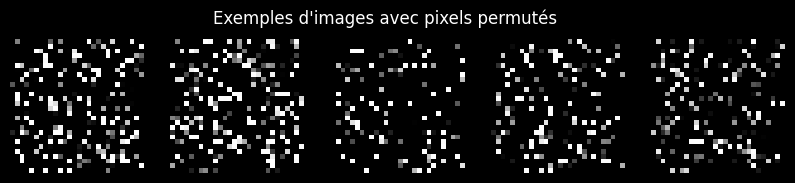

Train Epoch: 0 [0/60000 (0%)]	Loss: 2.335738
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.976557
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.451218
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.931051
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.891388
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.514768
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.491607
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.426507
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.584580
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.535828

Test set: Average loss: 0.4641, Accuracy: 8620/10000 (86%)

Train Epoch: 0 [0/60000 (0%)]	Loss: 2.372370
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.981776
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.342130
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.787936
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.611283
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.541950
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.661684
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.520882
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.313969
T

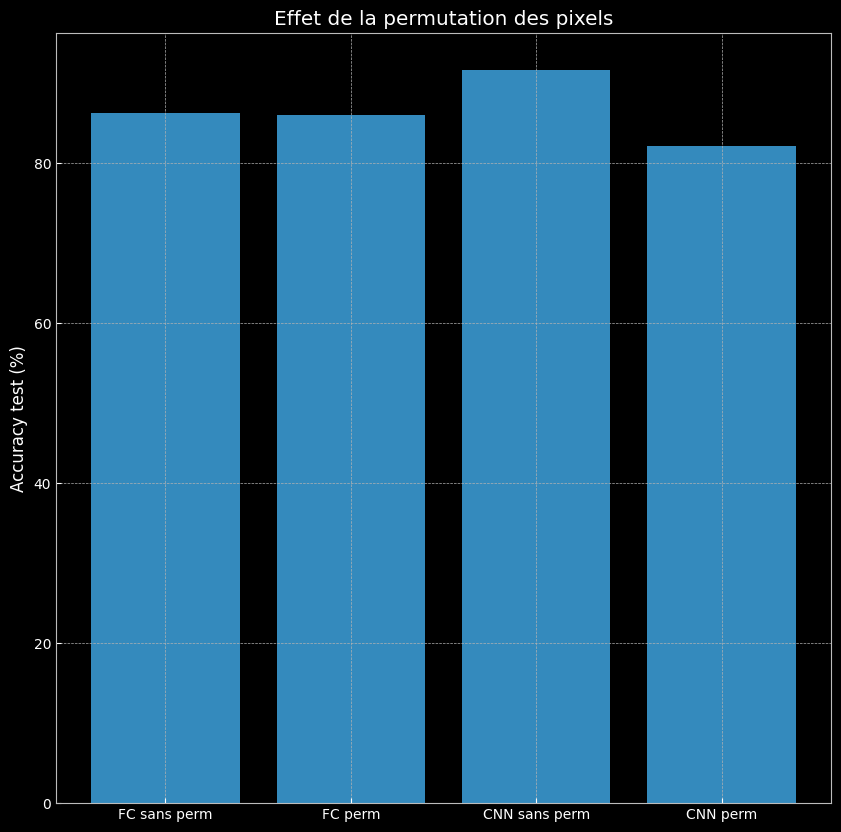

[86.2, 85.96, 91.65, 82.18]


In [26]:
perm = torch.randperm(784)

i = 5
for data, target in test_loader:
  # send to device
  data, target = data.to(device), target.to(device)

  # permute pixels
  data = data.view(-1, 28*28)
  data = data[:, perm]
  data = data.view(-1, 1, 28, 28)
    
  i -= 1
  if i <= 0:
    break

plt.figure(figsize=(10, 2))
for idx in range(5):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(data[idx].view(28, 28).cpu(), cmap='gray')
    plt.axis('off')
plt.suptitle("Exemples d'images avec pixels permutés")
plt.show()

accuracy_list = []
#FC2layer - Sans perm
model = FC2Layer(input_size, n_hidden, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model)
test(model)

#FC2layer - Avec perm
model = FC2Layer(input_size, n_hidden, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model, perm)
test(model, perm)

#CNN - Sans perm
model = CNN(input_size, n_features, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model)
test(model)

#CNN - Avec perm
model = CNN(input_size, n_features, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model,perm)
test(model,perm)

noms = ['FC sans perm', 'FC perm', 'CNN sans perm', 'CNN perm']
plt.figure()
plt.bar(noms, accuracy_list)
plt.ylabel("Accuracy test (%)")
plt.title("Effet de la permutation des pixels")
plt.show()
print(accuracy_list)

- Le FC n’est pas affecté par la permutation : il traite chaque pixel comme une entrée indépendante donc réordonner les pixels revient juste à réordonner les colonnes de sa première matrice de poids. Son accuracy reste à peu près la même ( 88.19% -> 85.85%)

- Le CNN est affecté : il passe de 95.19% à 84.23% car ses filtres regardent des groupes de pixels voisins et la permutation détruit ce voisinage.

Le CNN repose donc sur l’hypothèse de localité spatiale : les pixels proches sont corrélés et forment des motifs locaux (traits, bords), que l’on peut détecter partout dans l’image grâce au partage des poids.

9. Compute and display the confusion matrix (10×10) of the CNN trained on the original images, on the test set. Which digits are most often confused? Display 8 misclassified test images with their true and predicted labels.

In [27]:
from sklearn.metrics import confusion_matrix
model_cnn.eval()

vrai_label = []
predit_label = []

for data, target in test_loader:

    data, target = data.to(device), target.to(device)

    vrai_label.extend(target.cpu().numpy()) 

    output = model_cnn(data)

    predictions = torch.argmax(output, dim=1) # Argmax : Récupère la classe prédite.

    predit_label.extend(predictions.cpu().numpy()) # On recup de CPU + Convertit le tenseur PyTorch en tableau NumPy.

#- extend() ajoute les éléments du tableau individuellement dans la liste.

matrice = confusion_matrix(vrai_label, predit_label)
#Ligne : Vrai | Colonne : Predit
print(matrice)

dico_confusion_occ = {}

for i in range(10):
    dico_confusion_occ[i] = 0

    for j in range(10):
        if i != j:
            dico_confusion_occ[i] += matrice[i, j]
print(dico_confusion_occ)

print(f"La valeur la plus confondue est : {max(dico_confusion_occ, key=dico_confusion_occ.get)}")

[[ 955    0    6    0    0    2    7    3    7    0]
 [   1 1121    3    2    1    0    3    0    4    0]
 [   2    0  999    3    3    0    3    9   13    0]
 [   0    1   31  933    0   14    0    8   23    0]
 [   0    0    3    0  959    0    8    2    9    1]
 [   4    1    3   15    1  818    6    2   42    0]
 [   8    3    3    0    8    5  919    0   12    0]
 [   0    4   38    0    0    0    0  976   10    0]
 [   1    0    4   10    6    2    0   10  940    1]
 [   6    4    7    9   51   12    0   48   52  820]]
{0: 25, 1: 14, 2: 33, 3: 77, 4: 23, 5: 74, 6: 39, 7: 52, 8: 34, 9: 189}
La valeur la plus confondue est : 9


In [28]:
# Version on a aussi calculé les occurences des confusions d'un chiffre avec une valeur précise :
from sklearn.metrics import confusion_matrix

model_cnn.eval()

vrai_label = []
predit_label = []

for data, target in test_loader:

    data, target = data.to(device), target.to(device)

    vrai_label.extend(target.cpu().numpy()) 

    output = model_cnn(data)

    predictions = torch.argmax(output, dim=1) #Argmax : Récupère la classe prédite.

    predit_label.extend(predictions.cpu().numpy()) #On recup de CPU + Convertit le tenseur PyTorch en tableau NumPy.

#- extend() ajoute les éléments du tableau individuellement dans la liste.

matrice = confusion_matrix(vrai_label, predit_label)
#Ligne : Vrai | Colonne : Predit
print(matrice)

for i in range(10):
    for j in range(10):
        if i != j and matrice[i, j] > 25:
            print(i, "confondu avec", j, ":", matrice[i, j])

[[ 955    0    6    0    0    2    7    3    7    0]
 [   1 1121    3    2    1    0    3    0    4    0]
 [   2    0  999    3    3    0    3    9   13    0]
 [   0    1   31  933    0   14    0    8   23    0]
 [   0    0    3    0  959    0    8    2    9    1]
 [   4    1    3   15    1  818    6    2   42    0]
 [   8    3    3    0    8    5  919    0   12    0]
 [   0    4   38    0    0    0    0  976   10    0]
 [   1    0    4   10    6    2    0   10  940    1]
 [   6    4    7    9   51   12    0   48   52  820]]
3 confondu avec 2 : 31
5 confondu avec 8 : 42
7 confondu avec 2 : 38
9 confondu avec 4 : 51
9 confondu avec 7 : 48
9 confondu avec 8 : 52


10. Change the parameters of the models (number of feature maps, number of hidden units, number of epochs, learning rate)

In [29]:
class CNN_v2(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super(CNN_v2, self).__init__()
        self.n_feature = n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)
        self.fc1 = nn.Linear(n_feature*4*4, 50)
        self.fc2 = nn.Linear(50, 80)
        self.fc3 = nn.Linear(80, 110)
        self.fc4 = nn.Linear(110, 10)

    def forward(self, x, verbose=False):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = x.view(-1, self.n_feature*4*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        x = F.relu(x)
        x = self.fc4(x)
        x = F.log_softmax(x, dim=1)
        return x

n_features = 16 # number of feature maps

model_cnn_v2 = CNN_v2(input_size, n_features, output_size)
model_cnn_v2.to(device)
optimizer = optim.SGD(model_cnn_v2.parameters(), lr=0.0084, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_cnn_v2)))

for epoch in range(0, 10):
    train(epoch, model_cnn_v2)
    test(model_cnn_v2)


model_cnn_v2.eval()

vrai_label = []
predit_label = []

for data, target in test_loader:

    data, target = data.to(device), target.to(device)

    vrai_label.extend(target.cpu().numpy()) 

    output = model_cnn_v2(data)

    predictions = torch.argmax(output, dim=1) #Argmax : Récupère la classe prédite.

    predit_label.extend(predictions.cpu().numpy())
matrice = confusion_matrix(vrai_label, predit_label)
#Ligne : Vrai | Colonne : Predit
print(matrice)
for i in range(10):
    for j in range(10):
        if i != j and matrice[i, j] > 8:
            print(i, "confondu avec", j, ":", matrice[i, j])

Number of parameters: 33782
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.299074
Train Epoch: 0 [6400/60000 (11%)]	Loss: 2.305146
Train Epoch: 0 [12800/60000 (21%)]	Loss: 2.284528
Train Epoch: 0 [19200/60000 (32%)]	Loss: 2.245020
Train Epoch: 0 [25600/60000 (43%)]	Loss: 1.750443
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.798504
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.603749
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.427820
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.380916
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.290999

Test set: Average loss: 0.2467, Accuracy: 9247/10000 (92%)

Train Epoch: 1 [0/60000 (0%)]	Loss: 0.227929
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.236065
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.250405
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.139448
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.248831
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.147897
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.143994
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.072678
Train Epoch: 1 [51200/6

11. Analyze the results and the impact of these parameters, in particular the trade-off between number of parameters and accuracy.

L'augmentation de n_features = 16, l'ajout de couches cachées supplémentaires (fc2, fc3) et l'ajustement du taux d'apprentissage permettent de faire passer l'accuracy à 99 %, ce qui montre un vrai compromis où l'augmentation de la complexité et du nombre de paramètres du modèle améliore réellement sa capacité de généralisation et réduit les confusions par rapport au modèle initial